<a href="https://colab.research.google.com/github/elisabethcoller/CDD-Noise-Filtering-Algorithm/blob/main/microcontroller_algorithm/my_algorithm_11_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

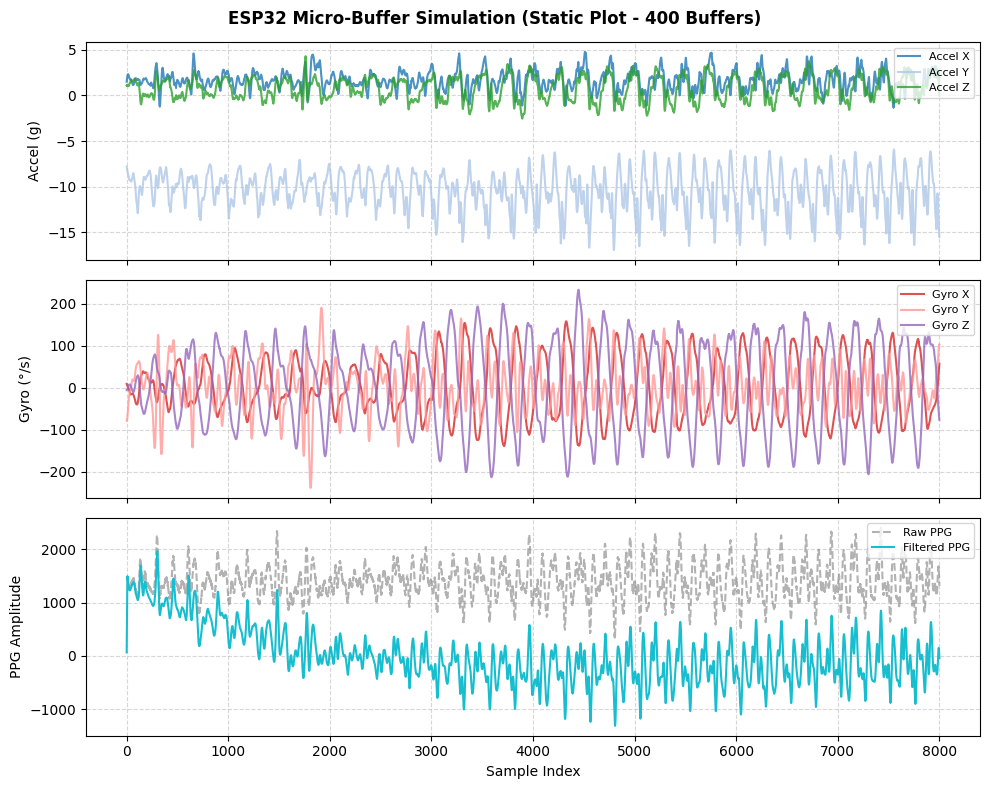

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter_zi, lfilter

# =====================================================================
# 1. CONFIGURATION & SETUP
# =====================================================================
CONFIG = {
    "file_path": "s3.csv",              # Update with your actual CSV file path
    "sampling_rate_hz": 125.0,          # 125 Hz sampling rate
    "buffer_size_samples": 20,          # Size of each micro-buffer (simulating ESP RAM chunk)
    "num_test_buffers": 400,              # Restrict simulation strictly to 5 buffers
    "ppg_filter": {
        "lowcut": 0.01,
        "highcut": 10.0,
        "order": 2
    },
    # Column mapping based on your provided schema
    "column_mapping": {
        "time": "sample_times_for_all_signals_apart_from_ecg",
        "ppg": "wrist_ppg",
        "gyro_x": "wrist_gyro_x",
        "gyro_y": "wrist_gyro_y",
        "gyro_z": "wrist_gyro_z",
        "accel_x": "wrist_low_noise_accelerometer_x",
        "accel_y": "wrist_low_noise_accelerometer_y",
        "accel_z": "wrist_low_noise_accelerometer_z"
    }
}

# =====================================================================
# 2. LOAD DATA & SLICE TO 5 BUFFERS
# =====================================================================
path = CONFIG["file_path"]
if not os.path.exists(path):
    raise FileNotFoundError(f"[!] Error: File '{path}' not found.")

df = pd.read_csv(path)
cols = CONFIG["column_mapping"]
buffer_size = CONFIG["buffer_size_samples"]
total_samples_needed = buffer_size * CONFIG["num_test_buffers"]

if len(df) < total_samples_needed:
    total_samples_needed = len(df)

df_subset = df.iloc[:total_samples_needed].copy()

times = df_subset[cols["time"]].values
raw_ppg = df_subset[cols["ppg"]].values
accel = df_subset[[cols["accel_x"], cols["accel_y"], cols["accel_z"]]].values
gyro = df_subset[[cols["gyro_x"], cols["gyro_y"], cols["gyro_z"]]].values

# =====================================================================
# 3. FILTER SETUP & BUFFERED PROCESSING LOOP
# =====================================================================
fs = CONFIG["sampling_rate_hz"]
low = CONFIG["ppg_filter"]["lowcut"]
high = CONFIG["ppg_filter"]["highcut"]
order = CONFIG["ppg_filter"]["order"]

nyq = 0.5 * fs
b, a = butter(order, [low / nyq, high / nyq], btype='band')

# Initialize stateful filter delay registers (zi)
zi_state = lfilter_zi(b, a) * 0

# Containers for processed data
x_data, raw_ppg_all, clean_ppg_all = [], [], []
ax_all, ay_all, az_all = [], [], []
gx_all, gy_all, gz_all = [], [], []

# Simulate the ESP pulling data buffer-by-buffer
for frame_idx in range(CONFIG["num_test_buffers"]):
    start_idx = frame_idx * buffer_size
    end_idx = start_idx + buffer_size

    if start_idx >= len(df_subset):
        break

    chunk_t = range(start_idx, end_idx)
    chunk_accel = accel[start_idx:end_idx]
    chunk_gyro = gyro[start_idx:end_idx]
    chunk_raw_ppg = raw_ppg[start_idx:end_idx]

    # Apply stateful causal filter per buffer chunk (preserving zi_state continuity)
    chunk_clean_ppg, zi_state = lfilter(b, a, chunk_raw_ppg, zi=zi_state)

    # Accumulate
    x_data.extend(chunk_t)
    raw_ppg_all.extend(chunk_raw_ppg)
    clean_ppg_all.extend(chunk_clean_ppg)

    ax_all.extend(chunk_accel[:, 0])
    ay_all.extend(chunk_accel[:, 1])
    az_all.extend(chunk_accel[:, 2])

    gx_all.extend(chunk_gyro[:, 0])
    gy_all.extend(chunk_gyro[:, 1])
    gz_all.extend(chunk_gyro[:, 2])

   #print(f"[Buffer {frame_idx + 1}/{CONFIG['num_test_buffers']}] Processed indices {start_idx} to {end_idx}")

# =====================================================================
# 4. STATIC PLOTTING
# =====================================================================
fig, (ax_accel, ax_gyro, ax_ppg) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f"ESP32 Micro-Buffer Simulation (Static Plot - {CONFIG['num_test_buffers']} Buffers)", fontsize=12, fontweight='bold')

# Accelerometer
ax_accel.plot(x_data, ax_all, label='Accel X', color='#1f77b4', alpha=0.8)
ax_accel.plot(x_data, ay_all, label='Accel Y', color='#aec7e8', alpha=0.8)
ax_accel.plot(x_data, az_all, label='Accel Z', color='#2ca02c', alpha=0.8)
ax_accel.set_ylabel("Accel (g)")
ax_accel.legend(loc='upper right', fontsize=8)
ax_accel.grid(True, linestyle='--', alpha=0.5)

# Gyroscope
ax_gyro.plot(x_data, gx_all, label='Gyro X', color='#d62728', alpha=0.8)
ax_gyro.plot(x_data, gy_all, label='Gyro Y', color='#ff9896', alpha=0.8)
ax_gyro.plot(x_data, gz_all, label='Gyro Z', color='#9467bd', alpha=0.8)
ax_gyro.set_ylabel("Gyro (°/s)")
ax_gyro.legend(loc='upper right', fontsize=8)
ax_gyro.grid(True, linestyle='--', alpha=0.5)

# PPG (Raw vs Clean)
ax_ppg.plot(x_data, raw_ppg_all, label='Raw PPG', color='gray', alpha=0.6, linestyle='--')
ax_ppg.plot(x_data, clean_ppg_all, label='Filtered PPG', color='#17becf', linewidth=1.5)
ax_ppg.set_ylabel("PPG Amplitude")
ax_ppg.set_xlabel("Sample Index")
ax_ppg.legend(loc='upper right', fontsize=8)
ax_ppg.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

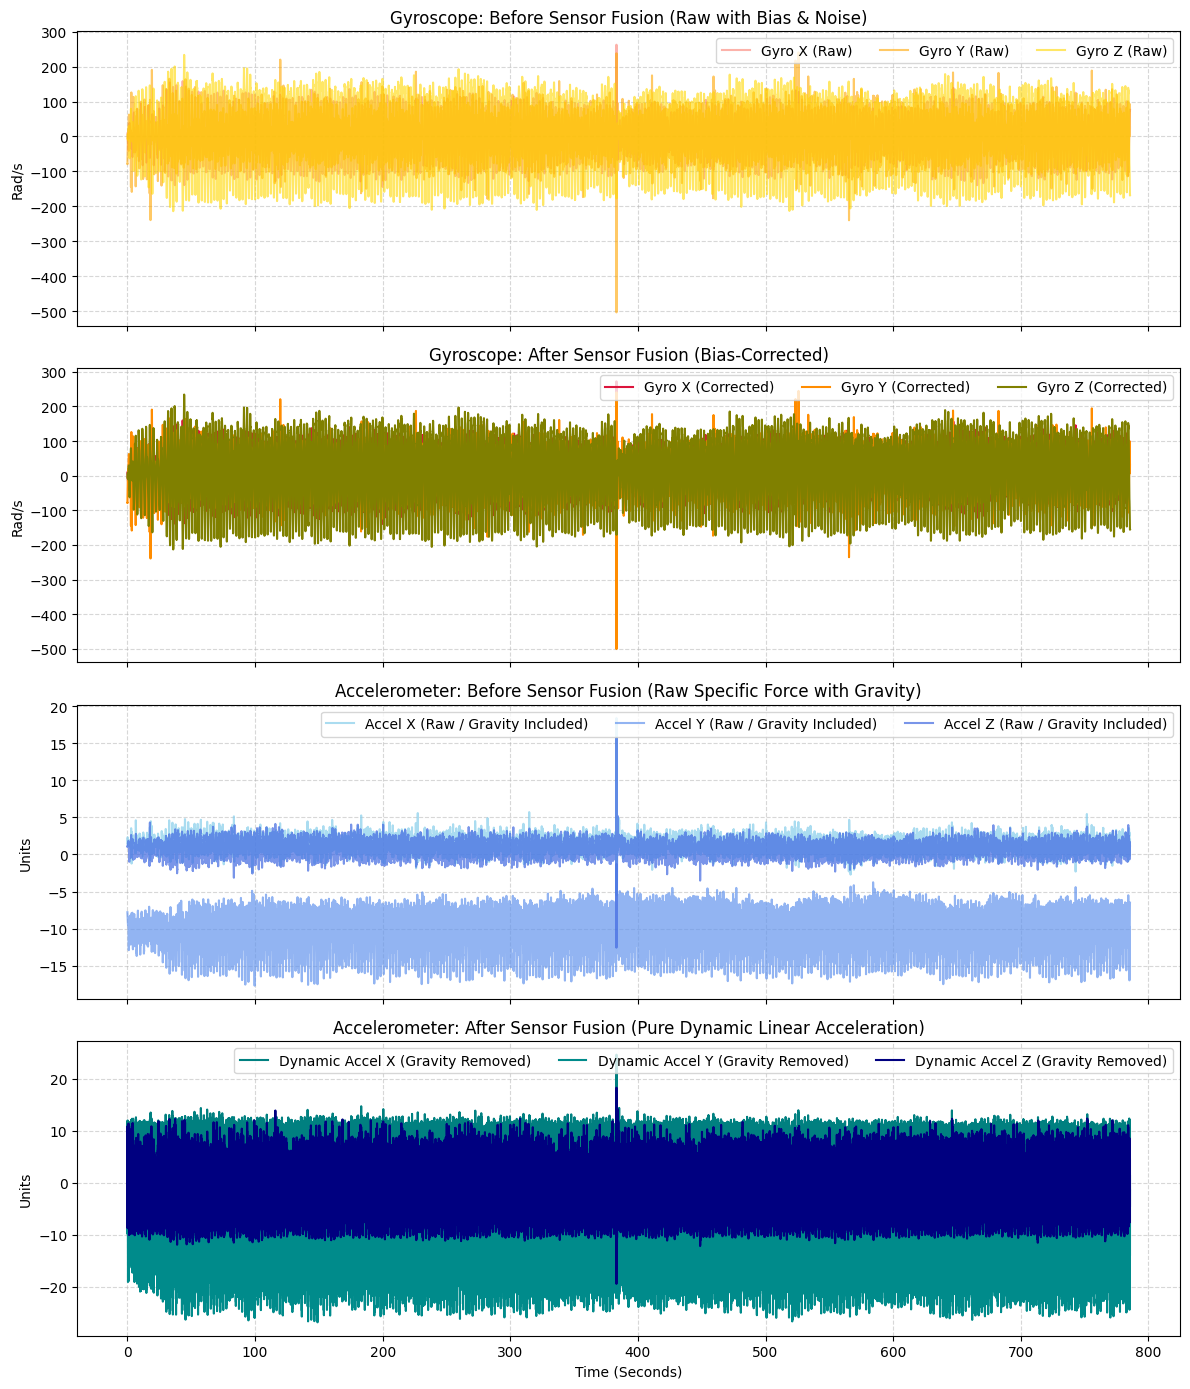

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def rot_matrix_from_quaternion(q):
    """Computes rotation matrix from quaternion [w, x, y, z]"""
    w, x, y, z = q
    return np.array([
        [1 - 2*(y**2 + z**2),     2*(x*y - z*w),         2*(x*z + y*w)],
        [    2*(x*y + z*w),   1 - 2*(x**2 + z**2),       2*(y*z - x*w)],
        [    2*(x*z - y*w),       2*(y*z + x*w),     1 - 2*(x**2 + y**2)]
    ])

def run_csv_imu_fusion():
    # 1. Load Real Data from CSV
    # Replace 'imu_raw_data.csv' with your actual filename and match column headers as needed
    df = pd.read_csv('s3.csv')

    # Extract time, raw gyroscope, and raw accelerometer columns
    # Assuming column names like: 'time', 'gx', 'gy', 'gz', 'ax', 'ay', 'az'
    t = df['sample_times_for_all_signals_apart_from_ecg'].values if 'time' in df.columns else np.arange(len(df)) / 100.0
    dt = np.mean(np.diff(t)) if len(t) > 1 else 0.01
    num_samples = len(df)

    gyro_raw = df[['wrist_gyro_x', 'wrist_gyro_y', 'wrist_gyro_z']].values  # Expected units: rad/s
    accel_raw = df[['wrist_low_noise_accelerometer_x', 'wrist_low_noise_accelerometer_y', 'wrist_low_noise_accelerometer_z']].values # Expected units: m/s² (or g, scale accordingly)

    # Global gravity vector (assuming Z-up coordinate frame; adjust to [0, 0, -9.81] if Z-down)
    g_global = np.array([0.0, 0.0, 9.81])

    # 2. EKF / Complementary Filter with Gyro Bias Estimation
    q_est = np.array([1.0, 0.0, 0.0, 0.0])
    bias_est = np.zeros(3) # Initial gyro bias estimate

    gyro_corrected = np.zeros_like(gyro_raw)
    dynamic_accel = np.zeros_like(accel_raw)

    # Filter tuning gains
    gain_bias = 0.001 # Learning rate for adaptive bias correction

    for i in range(num_samples):
        # A. Gyroscope Correction: Subtract estimated bias
        omega_meas = gyro_raw[i]
        omega_unbiased = omega_meas - bias_est
        gyro_corrected[i] = omega_unbiased

        # B. Orientation Prediction via Unbiased Gyro
        omega_step = omega_unbiased * dt
        angle = np.linalg.norm(omega_step)
        if angle > 1e-8:
            axis = omega_step / angle
            half_angle = angle / 2.0
            dq = np.array([np.cos(half_angle), *(axis * np.sin(half_angle))])
            w1, x1, y1, z1 = q_est
            w2, x2, y2, z2 = dq
            q_est = np.array([
                w1*w2 - x1*x2 - y1*y2 - z1*z2,
                w1*x2 + x2*w1 + y1*z2 - z1*y2,
                w1*y2 - x1*z2 + y1*w2 + z1*x2,
                w1*z2 + x1*y2 - y1*x2 + z1*w2
            ])
            q_est /= np.linalg.norm(q_est)

        # C. Accelerometer Correction (Gravity observation)
        R_est = rot_matrix_from_quaternion(q_est)
        g_expected = R_est.T @ g_global  # Expected gravity in sensor frame
        a_meas = accel_raw[i]

        # Sanity check magnitude (approx 1g = 9.81 m/s²; adjust if your data is in g-units)
        a_mag = np.linalg.norm(a_meas)
        if 5.0 < a_mag < 15.0:
            error_axis = np.cross(a_meas / a_mag, g_expected / np.linalg.norm(g_expected))
            bias_est += error_axis * gain_bias

        # D. Subtract predicted gravity to isolate Dynamic Linear Acceleration
        dynamic_accel[i] = a_meas - g_expected

    # 3. Plotting Results: Before vs After Sensor Fusion
    fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)
    axes = axes.flatten()

    # Panel 1: Gyroscope - Before (Raw)
    axes[0].plot(t, gyro_raw[:, 0], label='Gyro X (Raw)', color='salmon', alpha=0.6)
    axes[0].plot(t, gyro_raw[:, 1], label='Gyro Y (Raw)', color='orange', alpha=0.6)
    axes[0].plot(t, gyro_raw[:, 2], label='Gyro Z (Raw)', color='gold', alpha=0.6)
    axes[0].set_title('Gyroscope: Before Sensor Fusion (Raw with Bias & Noise)')
    axes[0].set_ylabel('Rad/s')
    axes[0].legend(loc='upper right', ncol=3)
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Panel 2: Gyroscope - After (Bias Corrected)
    axes[1].plot(t, gyro_corrected[:, 0], label='Gyro X (Corrected)', color='crimson')
    axes[1].plot(t, gyro_corrected[:, 1], label='Gyro Y (Corrected)', color='darkorange')
    axes[1].plot(t, gyro_corrected[:, 2], label='Gyro Z (Corrected)', color='olive')
    axes[1].set_title('Gyroscope: After Sensor Fusion (Bias-Corrected)')
    axes[1].set_ylabel('Rad/s')
    axes[1].legend(loc='upper right', ncol=3)
    axes[1].grid(True, linestyle='--', alpha=0.5)

    # Panel 3: Accelerometer - Before (Raw Specific Force)
    axes[2].plot(t, accel_raw[:, 0], label='Accel X (Raw / Gravity Included)', color='skyblue', alpha=0.7)
    axes[2].plot(t, accel_raw[:, 1], label='Accel Y (Raw / Gravity Included)', color='cornflowerblue', alpha=0.7)
    axes[2].plot(t, accel_raw[:, 2], label='Accel Z (Raw / Gravity Included)', color='royalblue', alpha=0.7)
    axes[2].set_title('Accelerometer: Before Sensor Fusion (Raw Specific Force with Gravity)')
    axes[2].set_ylabel('Units')
    axes[2].legend(loc='upper right', ncol=3)
    axes[2].grid(True, linestyle='--', alpha=0.5)

    # Panel 4: Accelerometer - After (Dynamic Linear Accel)
    axes[3].plot(t, dynamic_accel[:, 0], label='Dynamic Accel X (Gravity Removed)', color='teal')
    axes[3].plot(t, dynamic_accel[:, 1], label='Dynamic Accel Y (Gravity Removed)', color='darkcyan')
    axes[3].plot(t, dynamic_accel[:, 2], label='Dynamic Accel Z (Gravity Removed)', color='navy')
    axes[3].set_title('Accelerometer: After Sensor Fusion (Pure Dynamic Linear Acceleration)')
    axes[3].set_xlabel('Time (Seconds)')
    axes[3].set_ylabel('Units')
    axes[3].legend(loc='upper right', ncol=3)
    axes[3].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    run_csv_imu_fusion()